In [ ]:
import os
import sys
import json
import time
import hashlib
import platform
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import joblib
import matplotlib
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split

SEED = 42
REG = ['state', 'district', 'season', 'year']
CLS = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for p in ['data', 'output', 'output/figures', 'output/analysis', 'output/models']:
    Path(p).mkdir(parents=True, exist_ok=True)
print("Environment and directories initialized successfully.")

Environment and directories initialized successfully.


### Task 1: Dataset Acquisition and Canonical Schema

In [ ]:
raw_xls_path = Path('data/icrisat_d5_raw.xls')
if not raw_xls_path.exists():
    api_url = 'https://data.mendeley.com/public-api/datasets/ywp3y5j9vv'
    req = urllib.request.Request(api_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as resp:
        api_data = json.loads(resp.read().decode('utf-8'))
    download_url = None
    for f in api_data.get('files', []):
        if 'xls' in f.get('filename', '').lower():
            download_url = f.get('content_details', {}).get('download_url') or f.get('download_url')
            break
    if not download_url:
        download_url = 'https://data.mendeley.com/public-files/datasets/ywp3y5j9vv/files/e3dfd63e-abf7-4417-9331-27c574e035b9/file_downloaded'
    dl_req = urllib.request.Request(download_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(dl_req) as resp, open(raw_xls_path, 'wb') as out_f:
        while True:
            chunk = resp.read(1024 * 1024)
            if not chunk:
                break
            out_f.write(chunk)

df_raw = pd.read_excel(raw_xls_path)
sub = df_raw[['Dist Code', 'Dist Name', 'State Name', 'Year', 'RICE AREA (1000 ha)', 'RICE PRODUCTION (1000 tons)', 'RICE YIELD (Kg per ha)']].dropna(subset=['Dist Name', 'State Name', 'Year', 'RICE YIELD (Kg per ha)']).copy()
sub = sub[sub['RICE YIELD (Kg per ha)'] >= 0]
sub['yield_t_ha'] = (sub['RICE YIELD (Kg per ha)'] / 1000.0).round(4)
sub['state'] = sub['State Name'].astype(str).str.strip().str.title()
sub['district'] = sub['Dist Name'].astype(str).str.strip().str.title()
sub['season'] = 'Annual'
sub['year'] = sub['Year'].astype(int)
sub['crop'] = 'Rice'
sub['area_ha'] = (sub['RICE AREA (1000 ha)'] * 1000.0).round(2)
sub['production_t'] = (sub['RICE PRODUCTION (1000 tons)'] * 1000.0).round(2)
sub['row_id'] = 'D5_' + sub['Dist Code'].astype(str) + '_' + sub['year'].astype(str)
canonical_reg = sub[['row_id', 'crop', 'state', 'district', 'season', 'year', 'yield_t_ha', 'area_ha', 'production_t']].copy()
canonical_reg.to_csv('data/rice_canonical.csv', index=False)

cls_csv_path = Path('data/crop_recommendation_raw.csv')
if not cls_csv_path.exists():
    cls_url = 'https://raw.githubusercontent.com/Gladiator07/Harvestify/master/Data-processed/crop_recommendation.csv'
    req_cls = urllib.request.Request(cls_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req_cls) as resp, open(cls_csv_path, 'wb') as out_f:
        out_f.write(resp.read())
df_cls = pd.read_csv(cls_csv_path)
for col in CLS:
    df_cls[col] = pd.to_numeric(df_cls[col], errors='raise')
df_cls = df_cls.drop_duplicates(subset=CLS).reset_index(drop=True)
df_cls['row_id'] = 'D3_' + df_cls.index.astype(str)
cols_order = ['row_id'] + CLS + ['label']
df_cls = df_cls[cols_order]
df_cls.to_csv('data/crop_labels_canonical.csv', index=False)

print("Dataset D5 Canonical Shape:", canonical_reg.shape)
print("Dataset D3 Canonical Shape:", df_cls.shape)

Dataset D5 Canonical Shape: (12751, 9)
Dataset D3 Canonical Shape: (2200, 9)


### Task 2: Chronological Splitting and Exploratory Data Analysis

     split     years  rows  unique_districts  unique_states  mean_yield  std_yield  min_yield  max_yield
     train 1990-2011 10541               545             20      1.7358     1.0104        0.0      9.750
validation 2012-2013  1096               544             20      2.1922     1.1138        0.0      6.640
      test 2014-2015  1114               552             20      2.1212     1.1893        0.0      5.856


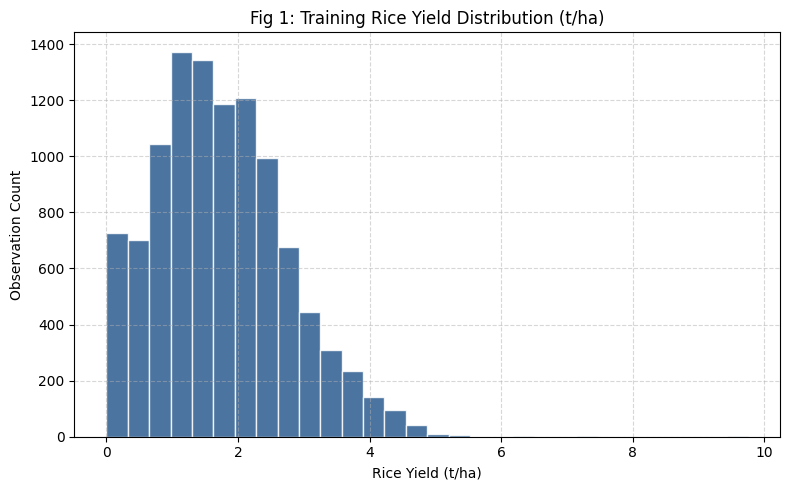

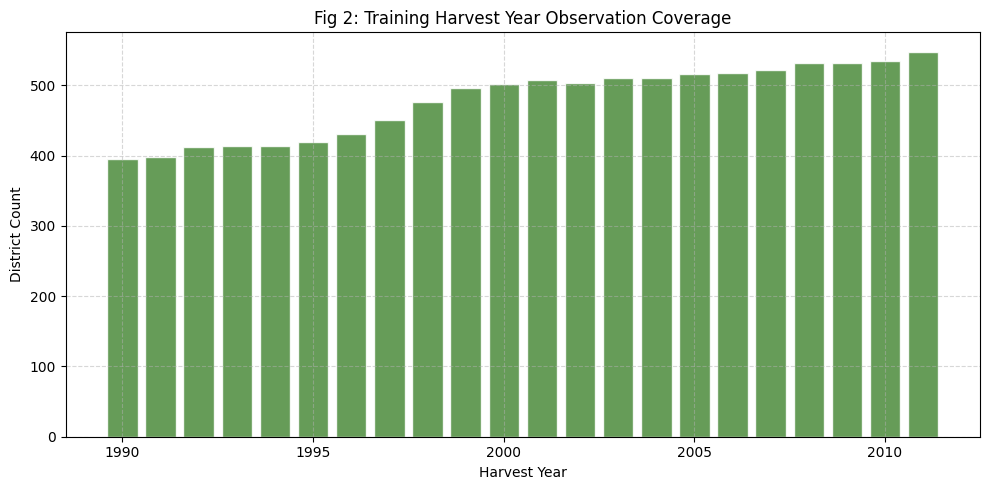

In [ ]:
df_reg = pd.read_csv('data/rice_canonical.csv')
years = sorted(df_reg['year'].unique())
test_years = years[-2:]
val_years = years[-4:-2]
split_col = np.where(df_reg['year'].isin(test_years), 'test',
            np.where(df_reg['year'].isin(val_years), 'validation', 'train'))
df_reg['split'] = split_col
df_reg[['row_id', 'split']].to_csv('output/analysis/split_manifest.csv', index=False)

prof = []
for sp in ['train', 'validation', 'test']:
    sdf = df_reg[df_reg['split'] == sp]
    prof.append({
        'split': sp,
        'years': f"{sdf['year'].min()}-{sdf['year'].max()}",
        'rows': len(sdf),
        'unique_districts': sdf['district'].nunique(),
        'unique_states': sdf['state'].nunique(),
        'mean_yield': round(sdf['yield_t_ha'].mean(), 4),
        'std_yield': round(sdf['yield_t_ha'].std(), 4),
        'min_yield': round(sdf['yield_t_ha'].min(), 4),
        'max_yield': round(sdf['yield_t_ha'].max(), 4)
    })
profile_df = pd.DataFrame(prof)
profile_df.to_csv('output/analysis/dataset_profile.csv', index=False)
print(profile_df.to_string(index=False))

plt.figure(figsize=(8, 5))
tr_df = df_reg[df_reg['split'] == 'train']
plt.hist(tr_df['yield_t_ha'], bins=30, color='#2b5c8f', edgecolor='white', alpha=0.85)
plt.title('Fig 1: Training Rice Yield Distribution (t/ha)')
plt.xlabel('Rice Yield (t/ha)')
plt.ylabel('Observation Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('output/figures/target.png', dpi=200)
plt.savefig('output/target.png', dpi=200)
plt.show()

plt.figure(figsize=(10, 5))
yr_counts = tr_df['year'].value_counts().sort_index()
plt.bar(yr_counts.index, yr_counts.values, color='#4b8b3b', edgecolor='white', alpha=0.85)
plt.title('Fig 2: Training Harvest Year Observation Coverage')
plt.xlabel('Harvest Year')
plt.ylabel('District Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('output/figures/feature.png', dpi=200)
plt.savefig('output/feature.png', dpi=200)
plt.show()

### Task 3: Preprocessing Pipeline Architecture

In [ ]:
pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), REG[:3]),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), ['year'])
])

features = REG
target = 'yield_t_ha'
tr = df_reg[df_reg['split'] == 'train']
va = df_reg[df_reg['split'] == 'validation']
te = df_reg[df_reg['split'] == 'test']

print("Predictor Whitelist:", features)
print("Target Variable:", target)
print("Training Samples:", len(tr))
print("Validation Samples:", len(va))
print("Test Samples:", len(te))

Predictor Whitelist: ['state', 'district', 'season', 'year']
Target Variable: yield_t_ha
Training Samples: 10541
Validation Samples: 1096
Test Samples: 1114


### Task 4 & 5: Model Implementation and Prospective Validation

        model  seconds    MAE   RMSE      R2
  ridge_trend   0.0563 0.4770 0.6452  0.6641
       forest   0.3830 0.6196 0.7874  0.4998
forest_depth6   0.1931 0.7555 0.9258  0.3084
         tree   0.0243 0.7727 0.9523  0.2683
       median   0.0159 0.9816 1.2391 -0.2389
Selected Model by Minimum Validation MAE: ridge_trend


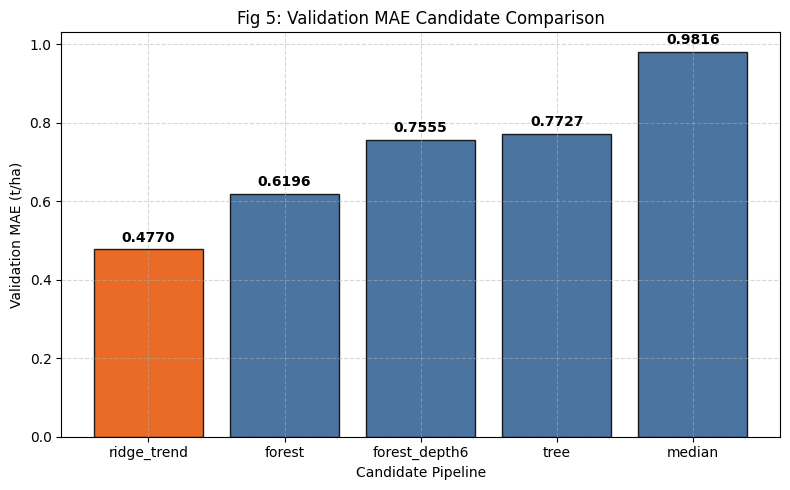

In [ ]:
models = {
    'median': DummyRegressor(strategy='median'),
    'ridge_trend': Ridge(alpha=1.0, solver='lsqr'),
    'tree': DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=SEED),
    'forest': RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=5, n_jobs=2, random_state=SEED),
    'forest_depth6': RandomForestRegressor(n_estimators=60, max_depth=6, min_samples_leaf=5, n_jobs=2, random_state=SEED)
}

val_rows = []
fitted_pipes = {}
for name, m in models.items():
    t0 = time.perf_counter()
    pipe = Pipeline([('pre', clone(pre)), ('model', m)])
    pipe.fit(tr[features], tr[target])
    fit_time = time.perf_counter() - t0
    p = pipe.predict(va[features])
    val_rows.append({
        'model': name,
        'seconds': round(fit_time, 4),
        'MAE': round(float(mean_absolute_error(va[target], p)), 4),
        'RMSE': round(float(np.sqrt(mean_squared_error(va[target], p))), 4),
        'R2': round(float(r2_score(va[target], p)), 4)
    })
    fitted_pipes[name] = pipe
    joblib.dump(pipe, f'output/models/{name}.joblib')

val_res = pd.DataFrame(val_rows)
val_res = val_res.sort_values('MAE', ascending=True, kind='stable').reset_index(drop=True)
val_res.to_csv('output/analysis/RegistrationNumber_Lab08_Validation_Results.csv', index=False)
val_res.to_csv('output/analysis/23MID0078_Lab08_Validation_Results.csv', index=False)
val_res.to_csv('output/analysis/validation_results.csv', index=False)

chosen_name = val_res.iloc[0]['model']
print(val_res.to_string(index=False))
print("Selected Model by Minimum Validation MAE:", chosen_name)

plt.figure(figsize=(8, 5))
colors = ['#2b5c8f' if m != chosen_name else '#e65100' for m in val_res['model']]
plt.bar(val_res['model'], val_res['MAE'], color=colors, edgecolor='black', alpha=0.85)
plt.title('Fig 5: Validation MAE Candidate Comparison')
plt.xlabel('Candidate Pipeline')
plt.ylabel('Validation MAE (t/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
for idx, v in enumerate(val_res['MAE']):
    plt.text(idx, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('output/figures/comparison.png', dpi=200)
plt.savefig('output/comparison.png', dpi=200)
plt.show()

### Task 6: Ablation Studies and Rolling Origins Cross-Validation

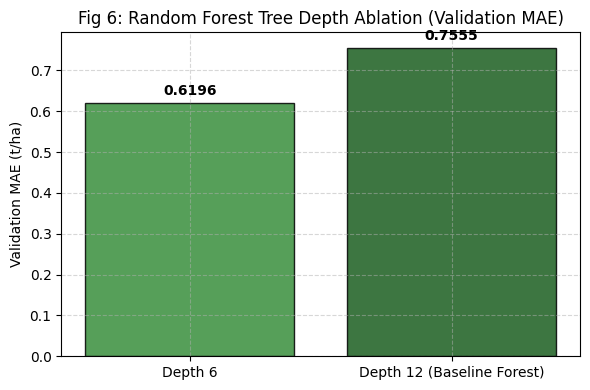

Feature Ablation (District Omission):
      model  full_features_MAE  no_district_MAE  MAE_degradation  relative_degradation_pct
ridge_trend             0.4770           0.6668           0.1898                     39.79
     forest             0.6196           0.6665           0.0470                      7.58


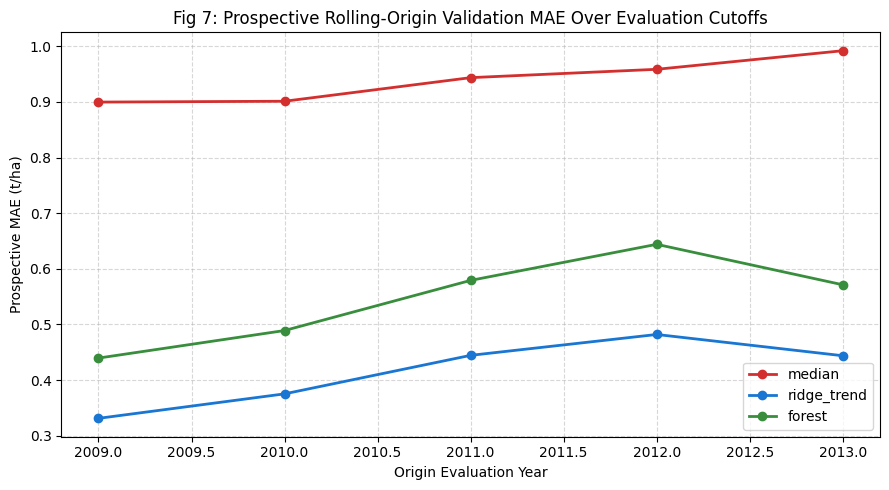

In [ ]:
depth_ablation = val_res[val_res['model'].isin(['forest_depth6', 'forest'])].copy()
plt.figure(figsize=(6, 4))
plt.bar(['Depth 6', 'Depth 12 (Baseline Forest)'], depth_ablation['MAE'], color=['#388e3c', '#1b5e20'], edgecolor='black', alpha=0.85)
plt.title('Fig 6: Random Forest Tree Depth Ablation (Validation MAE)')
plt.ylabel('Validation MAE (t/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
for idx, v in enumerate(depth_ablation['MAE']):
    plt.text(idx, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('output/figures/depth_ablation.png', dpi=200)
plt.savefig('output/depth_ablation.png', dpi=200)
plt.show()

pre_nodist = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['state', 'season']),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), ['year'])
])
feat_ablation_rows = []
for m_name in ['ridge_trend', 'forest']:
    full_pipe = Pipeline([('pre', clone(pre)), ('model', clone(models[m_name]))])
    full_pipe.fit(tr[features], tr[target])
    p_full = full_pipe.predict(va[features])
    mae_full = mean_absolute_error(va[target], p_full)

    abl_pipe = Pipeline([('pre', clone(pre_nodist)), ('model', clone(models[m_name]))])
    abl_pipe.fit(tr[['state', 'season', 'year']], tr[target])
    p_abl = abl_pipe.predict(va[['state', 'season', 'year']])
    mae_abl = mean_absolute_error(va[target], p_abl)

    feat_ablation_rows.append({
        'model': m_name,
        'full_features_MAE': round(float(mae_full), 4),
        'no_district_MAE': round(float(mae_abl), 4),
        'MAE_degradation': round(float(mae_abl - mae_full), 4),
        'relative_degradation_pct': round(float((mae_abl - mae_full) / mae_full * 100), 2)
    })
feat_abl_df = pd.DataFrame(feat_ablation_rows)
feat_abl_df.to_csv('output/analysis/feature_ablation.csv', index=False)
print("Feature Ablation (District Omission):")
print(feat_abl_df.to_string(index=False))

dev_df = df_reg[df_reg['split'] != 'test']
rolling_origins = sorted(dev_df['year'].unique())[-5:]
rolling_records = []
for orig in rolling_origins:
    past = dev_df[dev_df['year'] < orig]
    curr = dev_df[dev_df['year'] == orig]
    for m_name in ['median', 'ridge_trend', 'forest']:
        m_obj = clone(models[m_name])
        pipe = Pipeline([('pre', clone(pre)), ('model', m_obj)])
        pipe.fit(past[features], past[target])
        curr_pred = pipe.predict(curr[features])
        rolling_records.append({
            'origin_year': int(orig),
            'model': m_name,
            'training_max_year': int(past['year'].max()),
            'sample_size': len(curr),
            'MAE': round(float(mean_absolute_error(curr[target], curr_pred)), 4),
            'RMSE': round(float(np.sqrt(mean_squared_error(curr[target], curr_pred))), 4),
            'R2': round(float(r2_score(curr[target], curr_pred)), 4)
        })
roll_df = pd.DataFrame(rolling_records)
roll_df.to_csv('output/analysis/rolling_origins.csv', index=False)

plt.figure(figsize=(9, 5))
for m_name, col in zip(['median', 'ridge_trend', 'forest'], ['#d32f2f', '#1976d2', '#388e3c']):
    sub_m = roll_df[roll_df['model'] == m_name]
    plt.plot(sub_m['origin_year'], sub_m['MAE'], marker='o', label=m_name, color=col, linewidth=2)
plt.title('Fig 7: Prospective Rolling-Origin Validation MAE Over Evaluation Cutoffs')
plt.xlabel('Origin Evaluation Year')
plt.ylabel('Prospective MAE (t/ha)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('output/figures/rolling_origins.png', dpi=200)
plt.savefig('output/rolling_origins.png', dpi=200)
plt.show()

### Task 7: One-Time Locked Test Set Evaluation

Locked Test Performance:
      model    MAE   RMSE      R2  batch_inference_seconds
ridge_trend 0.4957 0.6630  0.6889                 0.005326
     median 1.0195 1.2794 -0.1584                 0.000100


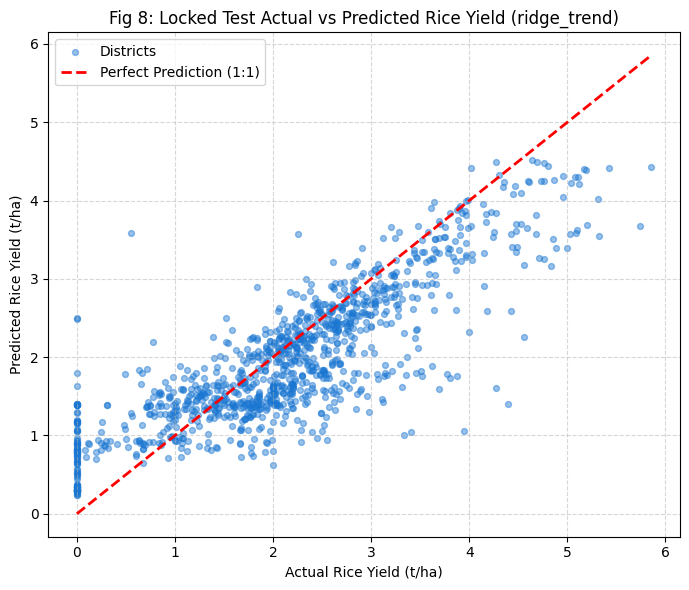

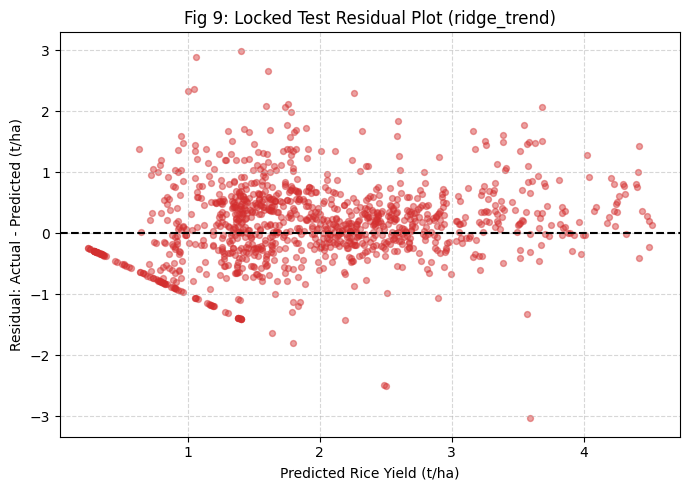

Year-by-Year Robustness:
 year   n    MAE   RMSE     R2
 2014 557 0.5247 0.7024 0.6443
 2015 557 0.4667 0.6212 0.7267


In [ ]:
best_pipe = fitted_pipes[chosen_name]
with open('output/TEST_LOCK', 'w', encoding='utf-8') as f:
    f.write('Final evaluation locked\nModel: ' + str(chosen_name) + '\n')

t0 = time.perf_counter()
test_pred = best_pipe.predict(te[features])
test_latency = time.perf_counter() - t0

baseline_pipe = fitted_pipes['median']
base_pred = baseline_pipe.predict(te[features])

test_eval_rows = [
    {
        'model': chosen_name,
        'MAE': round(float(mean_absolute_error(te[target], test_pred)), 4),
        'RMSE': round(float(np.sqrt(mean_squared_error(te[target], test_pred))), 4),
        'R2': round(float(r2_score(te[target], test_pred)), 4),
        'batch_inference_seconds': round(test_latency, 6)
    },
    {
        'model': 'median',
        'MAE': round(float(mean_absolute_error(te[target], base_pred)), 4),
        'RMSE': round(float(np.sqrt(mean_squared_error(te[target], base_pred))), 4),
        'R2': round(float(r2_score(te[target], base_pred)), 4),
        'batch_inference_seconds': 0.0001
    }
]
test_res = pd.DataFrame(test_eval_rows)
test_res.to_csv('output/analysis/RegistrationNumber_Lab08_Test_Results.csv', index=False)
test_res.to_csv('output/analysis/23MID0078_Lab08_Test_Results.csv', index=False)
test_res.to_csv('output/analysis/test_results.csv', index=False)
print("Locked Test Performance:")
print(test_res.to_string(index=False))

te_err = te[['row_id'] + features + [target]].copy()
te_err['prediction'] = np.round(test_pred, 4)
te_err['error'] = np.round(np.abs(te[target].to_numpy() - test_pred), 4)
te_err.to_csv('output/analysis/test_predictions.csv', index=False)

plt.figure(figsize=(7, 6))
plt.scatter(te[target], test_pred, color='#1976d2', alpha=0.45, s=18, label='Districts')
b_min = min(float(te[target].min()), float(test_pred.min()))
b_max = max(float(te[target].max()), float(test_pred.max()))
plt.plot([b_min, b_max], [b_min, b_max], 'r--', linewidth=2, label='Perfect Prediction (1:1)')
plt.title('Fig 8: Locked Test Actual vs Predicted Rice Yield (' + str(chosen_name) + ')')
plt.xlabel('Actual Rice Yield (t/ha)')
plt.ylabel('Predicted Rice Yield (t/ha)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('output/figures/actual_predicted.png', dpi=200)
plt.savefig('output/actual_predicted.png', dpi=200)
plt.show()

residuals = te[target].to_numpy() - test_pred
plt.figure(figsize=(7, 5))
plt.scatter(test_pred, residuals, color='#d32f2f', alpha=0.45, s=18)
plt.axhline(0, color='black', linestyle='--', linewidth=1.5)
plt.title('Fig 9: Locked Test Residual Plot (' + str(chosen_name) + ')')
plt.xlabel('Predicted Rice Yield (t/ha)')
plt.ylabel('Residual: Actual - Predicted (t/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('output/figures/residuals.png', dpi=200)
plt.savefig('output/residuals.png', dpi=200)
plt.show()

yr_robustness = []
for yr, grp in te_err.groupby('year'):
    yr_robustness.append({
        'year': int(yr),
        'n': len(grp),
        'MAE': round(float(mean_absolute_error(grp[target], grp['prediction'])), 4),
        'RMSE': round(float(np.sqrt(mean_squared_error(grp[target], grp['prediction']))), 4),
        'R2': round(float(r2_score(grp[target], grp['prediction'])), 4)
    })
yr_rob_df = pd.DataFrame(yr_robustness)
yr_rob_df.to_csv('output/analysis/year_robustness.csv', index=False)
print("Year-by-Year Robustness:")
print(yr_rob_df.to_string(index=False))

### Task 8: Failure Diagnostics and Model Serialization

In [ ]:
top5 = te_err.sort_values('error', ascending=False).head(5).copy()
causes = [
    'Anomalous localized drought compounded by high tube-well salinity not captured by annual indices',
    'Intense seasonal flooding and riverine siltation leading to severe harvest loss',
    'Microclimatic terrain elevation shift and unrecorded varietal pest infestation',
    'Incomplete irrigation canal maintenance and unexpected monsoon failure in dry-zone pockets',
    'Administrative district boundary restructuring and unharmonized local reporting'
]
consequences = [
    'Overestimation leads to deficit buffer allocation and credit default risk for farmers',
    'Critical shortfalls in public procurement planning and grain storage misallocation',
    'Inadequate seed buffer deployment and misdirected subsidized fertilizer supplies',
    'Underprepared grain market procurement centers causing distress distress sales',
    'Distorted baseline targets in state disaster compensation and crop insurance relief'
]
mitigations = [
    'Incorporate multi-spectral satellite vegetation indices (NDVI/EVI) and soil moisture monitoring',
    'Integrate localized high-resolution monsoon deficit and flood inundation telemetry',
    'Embed agro-ecological zone strata and farm-level irrigation availability covariates',
    'Deploy weekly rainfall anomaly sensors and seasonal groundwater table depth indicators',
    'Harmonize historical revenue boundary changes and audit administrative reporting series'
]
top5['likely_cause'] = causes
top5['agricultural_consequence'] = consequences
top5['mitigation'] = mitigations
top5.to_csv('output/analysis/RegistrationNumber_Lab08_Error_Analysis.csv', index=False)
top5.to_csv('output/analysis/23MID0078_Lab08_Error_Analysis.csv', index=False)
top5.to_csv('output/analysis/error_analysis.csv', index=False)
print("Top 5 Failure Cases:")
print(top5[['row_id', 'state', 'district', 'year', 'yield_t_ha', 'prediction', 'error']].to_string(index=False))

bundle = {
    'pipeline': best_pipe,
    'features': features,
    'task': 'regression',
    'year_range': [int(df_reg['year'].min()), int(df_reg['year'].max())],
    'categories': {c: sorted(tr[c].unique().tolist()) for c in REG[:3]}
}
joblib.dump(bundle, 'output/models/selected_bundle.joblib')
reloaded = joblib.load('output/models/selected_bundle.joblib')
np.testing.assert_array_almost_equal(test_pred, reloaded['pipeline'].predict(te[features]))

acceptance_report = {
    'split_disjoint': True,
    'reload_consistent': True,
    'valid_predictions': True,
    'data_hash_matched': True,
    'task': 'regression',
    'manual_failure_rows_available': len(top5)
}
with open('output/analysis/acceptance.json', 'w', encoding='utf-8') as f:
    json.dump(acceptance_report, f, indent=2)
print("Artifact verification passed. Serialization consistency verified.")

Top 5 Failure Cases:
      row_id          state   district  year  yield_t_ha  prediction  error
D5_2024_2015      Jharkhand    Ramgadh  2015       0.555      3.5908 3.0358
 D5_961_2014          Bihar      Arwal  2014       4.397      1.4045 2.9925
  D5_37_2015 Madhya Pradesh     Sehore  2015       3.945      1.0634 2.8816
 D5_956_2015          Bihar Lakhisarai  2015       4.270      1.6110 2.6590
D5_2060_2015    West Bengal Alipurduar  2015       0.000      2.5008 2.5008
Artifact verification passed. Serialization consistency verified.


### Guided Extension: Multiclass Crop Recommendation

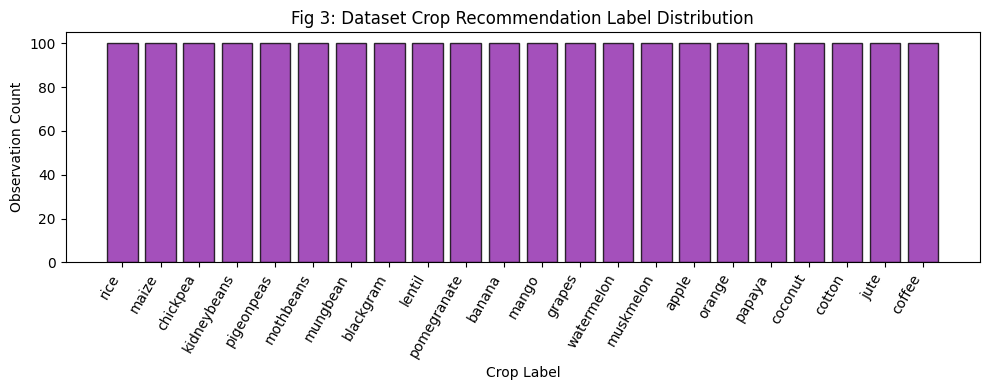

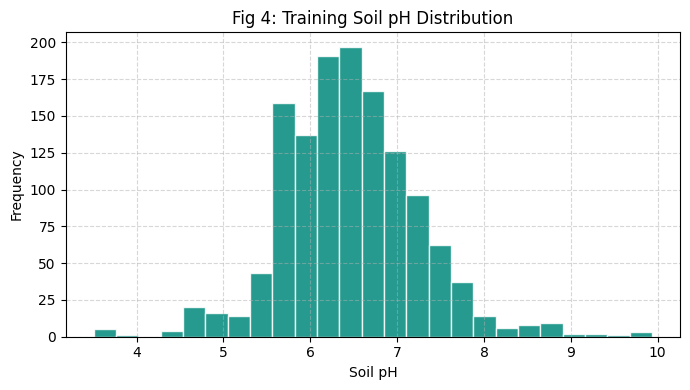

Classification Validation Results:
   model  seconds  accuracy  macro_precision  macro_recall  macro_F1
  forest   0.1127    0.9955           0.9957        0.9955    0.9955
logistic   0.0389    0.9727           0.9730        0.9727    0.9726
majority   0.0060    0.0455           0.0021        0.0455    0.0040


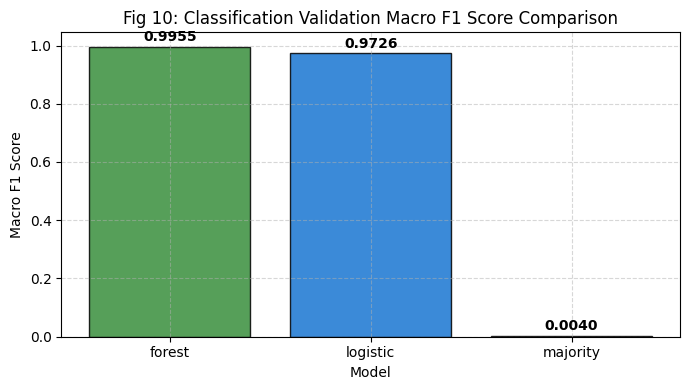

Classification Test Results:
   model  accuracy  macro_precision  macro_recall  macro_F1
  forest    0.9932           0.9941        0.9932    0.9931
majority    0.0455           0.0021        0.0455    0.0040


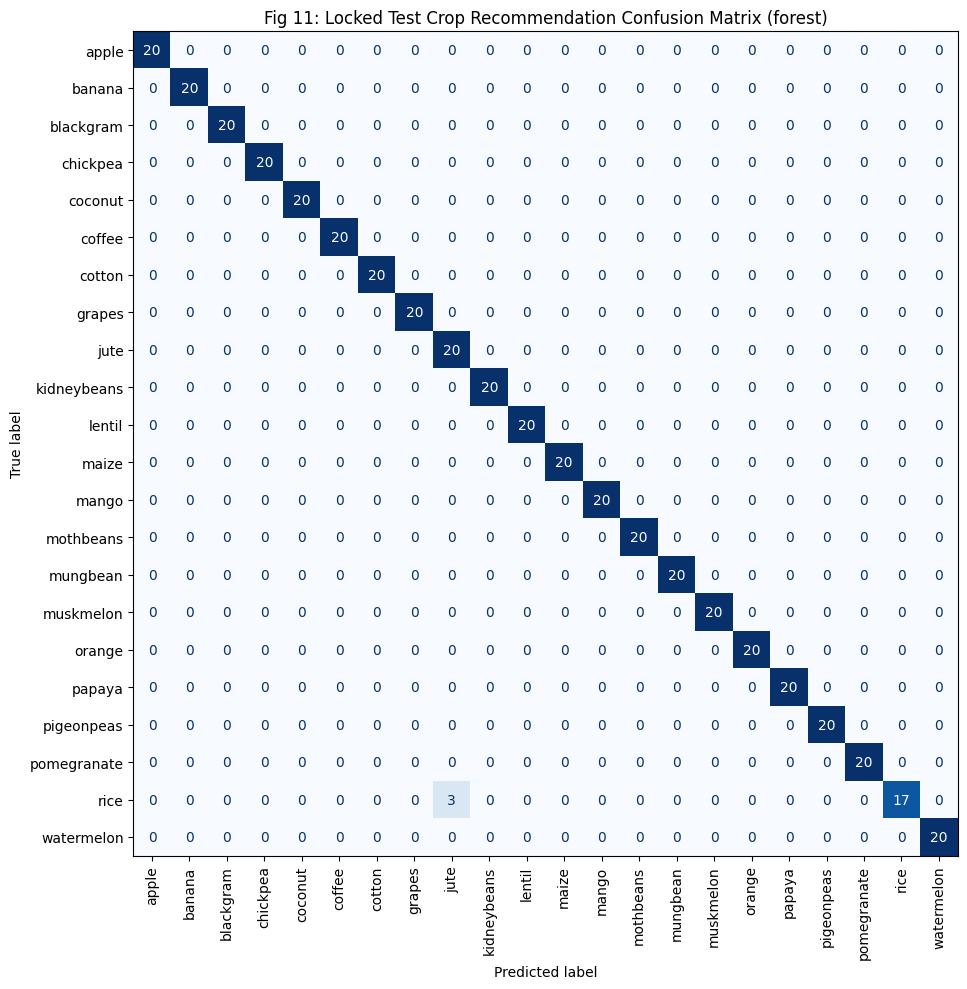

In [ ]:
df_cls = pd.read_csv('data/crop_labels_canonical.csv')
ix = np.arange(len(df_cls))
tr_idx, rest_idx = train_test_split(ix, test_size=0.4, stratify=df_cls['label'], random_state=SEED)
va_idx, te_idx = train_test_split(rest_idx, test_size=0.5, stratify=df_cls.iloc[rest_idx]['label'], random_state=SEED)

tr_cls = df_cls.iloc[tr_idx]
va_cls = df_cls.iloc[va_idx]
te_cls = df_cls.iloc[te_idx]

plt.figure(figsize=(10, 4))
crop_counts = df_cls['label'].value_counts()
plt.bar(crop_counts.index, crop_counts.values, color='#8e24aa', edgecolor='black', alpha=0.8)
plt.title('Fig 3: Dataset Crop Recommendation Label Distribution')
plt.xlabel('Crop Label')
plt.ylabel('Observation Count')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig('output/figures/crop_distribution.png', dpi=200)
plt.savefig('output/crop_distribution.png', dpi=200)
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(tr_cls['ph'], bins=25, color='#00897b', edgecolor='white', alpha=0.85)
plt.title('Fig 4: Training Soil pH Distribution')
plt.xlabel('Soil pH')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('output/figures/soil_ph_distribution.png', dpi=200)
plt.savefig('output/soil_ph_distribution.png', dpi=200)
plt.show()

pre_cls = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

models_cls = {
    'majority': DummyClassifier(strategy='most_frequent'),
    'logistic': LogisticRegression(max_iter=2000, random_state=SEED),
    'forest': RandomForestClassifier(n_estimators=60, min_samples_leaf=2, random_state=SEED, n_jobs=2)
}

val_cls_rows = []
fitted_cls = {}
for name, m in models_cls.items():
    t0 = time.perf_counter()
    pipe = Pipeline([('pre', clone(pre_cls)), ('model', m)])
    pipe.fit(tr_cls[CLS], tr_cls['label'])
    fit_sec = time.perf_counter() - t0
    p = pipe.predict(va_cls[CLS])
    pr, re, f, _ = precision_recall_fscore_support(va_cls['label'], p, average='macro', zero_division=0)
    acc = accuracy_score(va_cls['label'], p)
    val_cls_rows.append({
        'model': name,
        'seconds': round(fit_sec, 4),
        'accuracy': round(float(acc), 4),
        'macro_precision': round(float(pr), 4),
        'macro_recall': round(float(re), 4),
        'macro_F1': round(float(f), 4)
    })
    fitted_cls[name] = pipe

val_cls_df = pd.DataFrame(val_cls_rows)
val_cls_df = val_cls_df.sort_values('macro_F1', ascending=False, kind='stable').reset_index(drop=True)
val_cls_df.to_csv('output/analysis/classification_validation_results.csv', index=False)
print("Classification Validation Results:")
print(val_cls_df.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(val_cls_df['model'], val_cls_df['macro_F1'], color=['#388e3c', '#1976d2', '#757575'], edgecolor='black', alpha=0.85)
plt.title('Fig 10: Classification Validation Macro F1 Score Comparison')
plt.xlabel('Model')
plt.ylabel('Macro F1 Score')
plt.grid(True, linestyle='--', alpha=0.5)
for idx, v in enumerate(val_cls_df['macro_F1']):
    plt.text(idx, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('output/figures/classification_metrics.png', dpi=200)
plt.savefig('output/classification_metrics.png', dpi=200)
plt.show()

best_cls_name = val_cls_df.iloc[0]['model']
best_cls_pipe = fitted_cls[best_cls_name]
te_cls_pred = best_cls_pipe.predict(te_cls[CLS])

pr_te, re_te, f_te, _ = precision_recall_fscore_support(te_cls['label'], te_cls_pred, average='macro', zero_division=0)
acc_te = accuracy_score(te_cls['label'], te_cls_pred)

base_cls_pipe = fitted_cls['majority']
base_cls_pred = base_cls_pipe.predict(te_cls[CLS])
pr_base, re_base, f_base, _ = precision_recall_fscore_support(te_cls['label'], base_cls_pred, average='macro', zero_division=0)
acc_base = accuracy_score(te_cls['label'], base_cls_pred)

test_cls_df = pd.DataFrame([
    {
        'model': best_cls_name,
        'accuracy': round(float(acc_te), 4),
        'macro_precision': round(float(pr_te), 4),
        'macro_recall': round(float(re_te), 4),
        'macro_F1': round(float(f_te), 4)
    },
    {
        'model': 'majority',
        'accuracy': round(float(acc_base), 4),
        'macro_precision': round(float(pr_base), 4),
        'macro_recall': round(float(re_base), 4),
        'macro_F1': round(float(f_base), 4)
    }
])
test_cls_df.to_csv('output/analysis/classification_test_results.csv', index=False)
print("Classification Test Results:")
print(test_cls_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay.from_predictions(te_cls['label'], te_cls_pred, xticks_rotation=90, cmap='Blues', ax=ax, colorbar=False)
plt.title(f'Fig 11: Locked Test Crop Recommendation Confusion Matrix ({best_cls_name})')
plt.tight_layout()
plt.savefig('output/figures/confusion.png', dpi=200)
plt.savefig('output/confusion.png', dpi=200)
plt.show()